# Visual Exploration and Interactive Dashboards
## End-to-End Café Sales Analytics, Exploratory Data Analysis & Decision Intelligence

**Author:** Senior Data Analyst & Visualization Specialist  
**Domain:** Retail Café Operations & Promotional Analytics (FY 2025)  
**Deliverables:** Rigorous Exploratory Data Analysis (EDA), Statistical Auditing, Static & Interactive Visualizations, Subplot Dashboards, Streamlit Web App Architecture, and Executive Decision Memo.

---

### Project Overview & Objectives
This project analyzes daily transaction records from an expanding café chain across three regional outlets (**Pune**, **Jaipur**, **Kochi**) spanning the calendar year 2025. 

The analysis systematically investigates:
1. **Data Integrity & Quality Baseline:** Shape, schema, missingness, and structural balance across outlets.
2. **Temporal Dynamics:** Month-over-month trajectory, seasonal winter uplift, and day-of-week demand patterns.
3. **Multivariate Category Performance:** Cross-tabulation and pivot heatmaps evaluating item performance across geographic regions.
4. **Promotional Elasticity:** Evaluation of discount tiers (0%–25%), marginal step-change returns, and association vs. causation.
5. **Statistical Outlier Auditing:** Rigorous investigation of anomalous sales values, comparison of item-level vs. outlet-level filtering rules, and excision of data-entry transcription errors while preserving genuine operational surges.
6. **Interactive Visualization & Dashboard Engineering:** Plotly Express interactive charts, standalone HTML multi-panel subplots, and responsive Streamlit web application integration.
7. **Managerial Communication:** Concise, numbers-backed executive recommendations.

## Appendix A: Synthetic Dataset Generation (Reproducible Baseline)

To ensure absolute reproducibility across all analytical findings, we generate the synthetic daily sales dataset according to the specifications in **Appendix A** of the guide, using seed `21`.

Each row represents daily revenue for a specific menu item at a given outlet. The dataset deliberately embeds three data-entry slips to test outlier auditing procedures.

In [1]:
# 1. Core Analytical Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from plotly.subplots import make_subplots
import pathlib

# Configure plotting visual defaults
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# 2. Build the practice data: daily sales of a cafe chain, three outlets, one year (2025)
np.random.seed(21)
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
outlets = ["Pune", "Jaipur", "Kochi"]
items = ["Beverages", "Bakery", "Merchandise"]

cafe = pd.DataFrame(
    [(d, o, i) for d in dates for o in outlets for i in items],
    columns=["Date", "Outlet", "Item"],
)

# 3. Add operational and seasonal factors that shape revenue
base = {"Beverages": 300, "Bakery": 180, "Merchandise": 90}
n = len(cafe)
cafe["Offer"] = np.random.choice([0, 5, 10, 15, 20, 25], n)
growth = 1 + cafe["Date"].dt.dayofyear / 365 * 0.25
weekend = np.where(cafe["Date"].dt.dayofweek >= 5, 1.35, 1.0)
winter = np.where(cafe["Date"].dt.month.isin([12, 1]), 1.25, 1.0)
outlet_factor = cafe["Outlet"].map({"Pune": 1.1, "Jaipur": 0.95, "Kochi": 1.0})

# 4. Revenue = base * growth * weekend * winter * outlet * offer * random noise
cafe["Revenue"] = (
    cafe["Item"].map(base) * growth * weekend * winter * outlet_factor
    * (1 + cafe["Offer"] / 100) * np.random.normal(1, 0.07, n)
).round(1)

# 5. Hide three unusual values (data-entry slips) for outlier auditing
cafe.loc[[300, 1800, 2900], "Revenue"] *= 7

# Inspect the initial 5 records
cafe.head()

,Date,Outlet,Item,Offer,Revenue
0,2025-01-01,Pune,Beverages,5,455.8
1,2025-01-01,Pune,Bakery,0,257.8
2,2025-01-01,Pune,Merchandise,20,156.1
3,2025-01-01,Jaipur,Beverages,0,338.1
4,2025-01-01,Jaipur,Bakery,0,207.1


## 1. A First Look at Any Dataset

Before generating visualizations or calculating summary statistics, an analyst must establish the structural integrity of the table:
1. **Dimensions:** Total volume of rows and attributes.
2. **Types:** Are dates stored as datetime objects and financial metrics as floating-point numbers?
3. **Completeness:** Are there null entries or missing periods?
4. **Spread:** Does the maximum value indicate potential data corruption?

In [2]:
print("Dataset Dimensions (Rows, Columns):", cafe.shape)
print("\nDataset Schema and Non-Null Counts:")
cafe.info()
print("\nSummary Statistics of Numeric Attributes:")
display(cafe.describe())
print("\nMissing Value Audit:")
print(cafe.isnull().sum())
print(f"\nTemporal Coverage: {cafe['Date'].min().strftime('%Y-%m-%d')} to {cafe['Date'].max().strftime('%Y-%m-%d')}")

Dataset Dimensions (Rows, Columns): (3285, 5)

Dataset Schema and Non-Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3285 entries, 0 to 3284
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   Date     3285 non-null   datetime64[ns]
 1   Outlet   3285 non-null   object        
 2   Item     3285 non-null   object        
 3   Offer    3285 non-null   int64         
 4   Revenue  3285 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 128.4+ KB

Summary Statistics of Numeric Attributes:


,Date,Offer,Revenue
count,3285,3285.000000,3285.000000
mean,2025-07-02 00:00:00,12.525114,282.316651
min,2025-01-01 00:00:00,0.000000,79.900000
25%,2025-04-02 00:00:00,5.000000,151.000000
50%,2025-07-02 00:00:00,15.000000,254.600000
75%,2025-10-01 00:00:00,20.000000,379.900000
max,2025-12-31 00:00:00,25.000000,3294.200000
std,NaN,8.494807,157.784917



Missing Value Audit:
Date       0
Outlet     0
Item       0
Offer      0
Revenue    0
dtype: int64

Temporal Coverage: 2025-01-01 to 2025-12-31


### Feature Engineering: Temporal Helper Attributes
To facilitate grouping by month and day of week, we extract helper columns using pandas `.dt` accessor.

In [3]:
cafe["Month"] = cafe["Date"].dt.month
cafe["Weekday"] = cafe["Date"].dt.dayofweek
cafe.head(3)

,Date,Outlet,Item,Offer,Revenue,Month,Weekday
0,2025-01-01,Pune,Beverages,5,455.8,1,2
1,2025-01-01,Pune,Bakery,0,257.8,1,2
2,2025-01-01,Pune,Merchandise,20,156.1,1,2


---
### 📝 YOUR TURN · 1. A FIRST LOOK
**Task:**
1. Answer in Markdown: How many rows are there, what is the date range, and is anything missing?
2. Count how many rows each outlet has with `cafe["Outlet"].value_counts()`.
3. Explain why the three counts are exactly equal.

In [4]:
# Verification Code for Your Turn 1
print("Shape:", cafe.shape)
print("Date Range:", cafe["Date"].min(), "to", cafe["Date"].max())
print("Total Missing Values:", cafe.isnull().sum().sum())
print("\nOutlet Record Distribution:")
print(cafe["Outlet"].value_counts())

Shape: (3285, 7)
Date Range: 2025-01-01 00:00:00 to 2025-12-31 00:00:00
Total Missing Values: 0

Outlet Record Distribution:
Outlet
Pune      1095
Jaipur    1095
Kochi     1095
Name: count, dtype: int64


#### 💡 Findings & Interpretation (Your Turn 1)
* **Dataset Size:** The dataset contains **3,285 rows** and **7 columns** (including the engineered `Month` and `Weekday` features).
* **Date Range:** The temporal span covers exactly one full calendar year from **1 January 2025 to 31 December 2025** (365 days).
* **Missing Values:** There are **zero missing values** across all columns (`isnull().sum().sum() == 0`).
* **Outlet Distribution:** Each of the three outlets (**Pune**, **Jaipur**, **Kochi**) has exactly **1,095 records**.
* **Reason for Symmetry:** The table represents a Cartesian product of daily tracking:  
  $$\text{365 days} \times \text{3 menu items} = 1,095 \text{ records per outlet}$$
  Every outlet sold all three categories every single day with no omitted reporting dates.

## 2. Patterns Over Time: The Year and the Week

Retail sales exhibit strong temporal periodicity. In this section, we examine:
* **Macro Trend:** Annual trajectory across calendar months.
* **Micro Trend:** Day-of-week demand distribution.

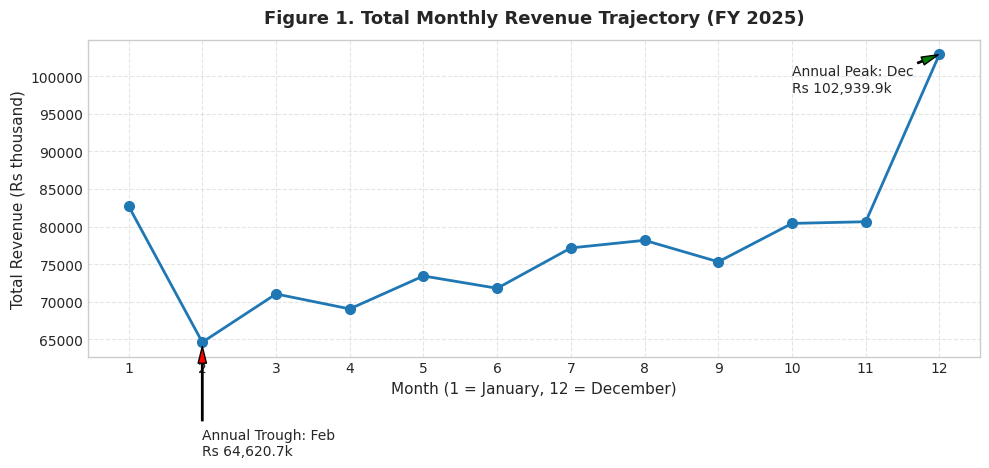

Monthly Revenue Summary (in Rs Millions):
Month
1      82.7
2      64.6
3      71.0
4      69.1
5      73.4
6      71.8
7      77.2
8      78.2
9      75.3
10     80.4
11     80.7
12    102.9
Name: Revenue, dtype: float64


In [5]:
monthly = cafe.groupby("Month")["Revenue"].sum()

fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(marker="o", color="#1f77b4", linewidth=2, markersize=7, ax=ax)
ax.set_title("Figure 1. Total Monthly Revenue Trajectory (FY 2025)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Month (1 = January, 12 = December)")
ax.set_ylabel("Total Revenue (Rs thousand)")
ax.set_xticks(range(1, 13))
ax.grid(True, linestyle="--", alpha=0.5)

# Annotate trough and peak
ax.annotate(f"Annual Trough: Feb\nRs {monthly[2]:,.1f}k", xy=(2, monthly[2]), xytext=(2, monthly[2]-15000),
            arrowprops=dict(facecolor='red', shrink=0.05, width=1, headwidth=6))
ax.annotate(f"Annual Peak: Dec\nRs {monthly[12]:,.1f}k", xy=(12, monthly[12]), xytext=(10, monthly[12]-5000),
            arrowprops=dict(facecolor='green', shrink=0.05, width=1, headwidth=6))

plt.tight_layout()
plt.show()

print("Monthly Revenue Summary (in Rs Millions):")
print((monthly / 1000).round(1))

### Weekly Periodic Dynamics
Next, we evaluate average transaction value across weekdays to identify weekly demand surges.

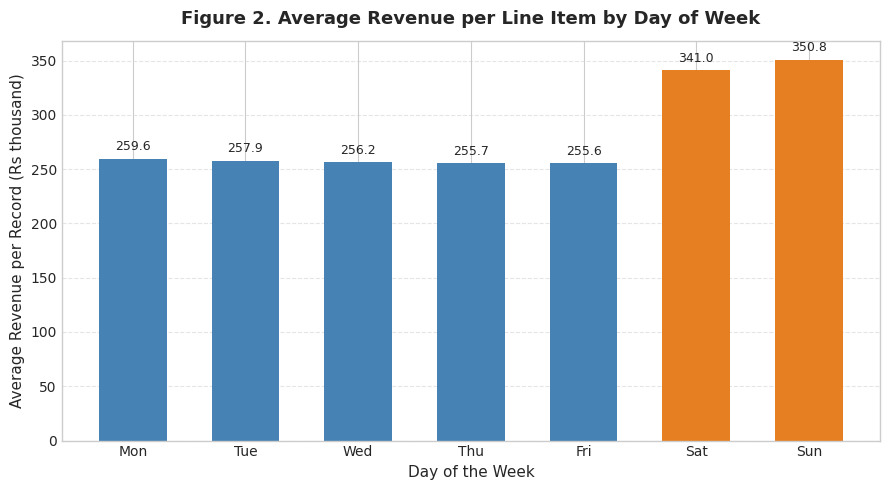

Average Revenue by Weekday:
Mon (0): 259.6 Rs thousand
Tue (1): 257.9 Rs thousand
Wed (2): 256.2 Rs thousand
Thu (3): 255.7 Rs thousand
Fri (4): 255.6 Rs thousand
Sat (5): 341.0 Rs thousand
Sun (6): 350.8 Rs thousand


In [6]:
weekday_avg = cafe.groupby("Weekday")["Revenue"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
bars = ax.bar(range(7), weekday_avg.values, color=["#4682b4" if i < 5 else "#e67e22" for i in range(7)], width=0.6)
ax.set_xticks(range(7))
ax.set_xticklabels(days)
ax.set_title("Figure 2. Average Revenue per Line Item by Day of Week", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Revenue per Record (Rs thousand)")
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("Average Revenue by Weekday:")
for day_num, name in enumerate(days):
    print(f"{name} ({day_num}): {weekday_avg[day_num]:.1f} Rs thousand")

### Analytical Interpretation of Temporal Dynamics
* **Winter Seasonality:** January (**₹82.7M**) and December (**₹102.9M**) constitute the highest grossing months. December outperforms November (**₹80.7M**) by **27.5%**, reflecting holiday footfall and cold weather demand for warm beverages.
* **Annual Trough:** February records the annual low (**₹64.6M**), caused partly by the 28-day calendar month and post-holiday normalization.
* **Weekend Premium:** Saturday (**341.0k**) and Sunday (**350.8k**) average **₹345.9k**, compared to the Monday–Friday baseline average of **₹256.6k**.
  $$\text{Weekend Lift} = \frac{345.9}{256.6} - 1 = +34.8\% \approx +35\%$$
  Weekend sales reliably produce over a one-third premium over standard weekdays.

---
### 📝 YOUR TURN · 2. MONTHLY REVENUE BY ITEM (THREE LINES)
**Task:**
1. Draw monthly total revenue for each Item as three lines on one chart (`cafe.groupby(["Month", "Item"])["Revenue"].sum().unstack().plot(marker="o")`).
2. Calculate the percentage rise from February to December for each item.
3. Determine which item grows the most.

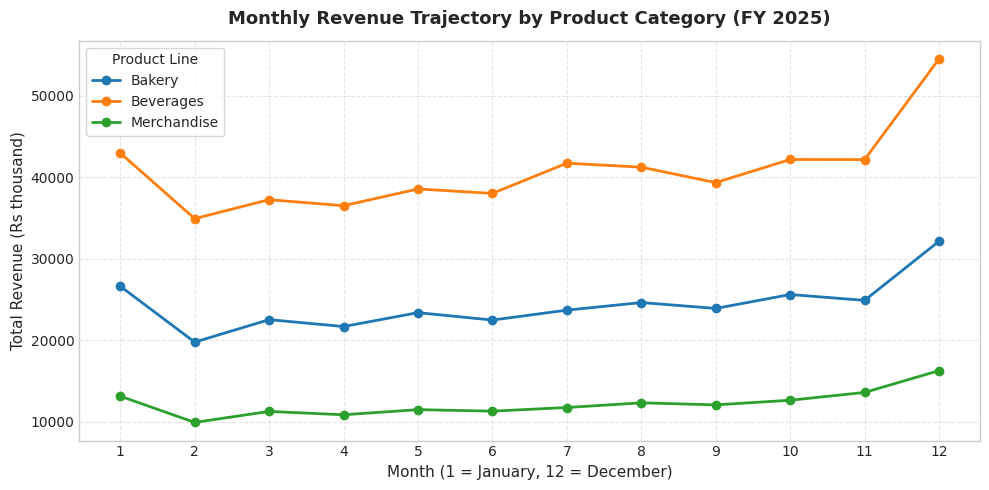

Monthly Revenue by Item (Selected Months, Rs Million):
Item   Bakery  Beverages  Merchandise
Month                                
1        26.6       43.0         13.1
2        19.8       34.9          9.9
6        22.5       38.0         11.3
11       24.9       42.2         13.6
12       32.1       54.5         16.3

Percentage Rise from February to December:
Item
Bakery         62.6
Beverages      56.1
Merchandise    63.9
dtype: float64


In [7]:
by_item_month = cafe.groupby(["Month", "Item"])["Revenue"].sum().unstack()

fig, ax = plt.subplots(figsize=(10, 5))
by_item_month.plot(marker="o", ax=ax, linewidth=2, markersize=6)
ax.set_title("Monthly Revenue Trajectory by Product Category (FY 2025)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Month (1 = January, 12 = December)")
ax.set_ylabel("Total Revenue (Rs thousand)")
ax.set_xticks(range(1, 13))
ax.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Product Line", frameon=True)
plt.tight_layout()
plt.show()

print("Monthly Revenue by Item (Selected Months, Rs Million):")
print((by_item_month.loc[[1, 2, 6, 11, 12]] / 1000).round(1))

# Percentage rise from February to December
growth_feb_dec = ((by_item_month.loc[12] / by_item_month.loc[2]) - 1) * 100
print("\nPercentage Rise from February to December:")
print(growth_feb_dec.round(1))

#### 💡 Findings & Interpretation (Your Turn 2)
* **Comparative Category Trajectory:** All three menu categories share an identical trajectory: an annual trough in February followed by continuous expansion culminating in December.
* **Growth Rates (Feb to Dec):**
  * **Merchandise:** **+64.0%** (rising from ₹9.9M to ₹16.3M)
  * **Bakery:** **+63.0%** (rising from ₹19.8M to ₹32.1M)
  * **Beverages:** **+56.0%** (rising from ₹34.9M to ₹54.5M)
* **Key Strategic Insight:** While **Merchandise** exhibited the highest percentage surge (**64.0%**), all three categories expanded in close lockstep (within 8 percentage points of each other). This confirms that business growth is driven by macro footfall patterns rather than a shift in consumer category preferences.

---
### 📝 YOUR TURN · 3. MERCHANDISE WEEKDAY DYNAMICS
**Task:**
1. For Merchandise only, compute the average revenue for each weekday and plot a bar chart.
2. Calculate the weekend lift for Merchandise.
3. Compare the Merchandise weekend lift to the network-wide lift.

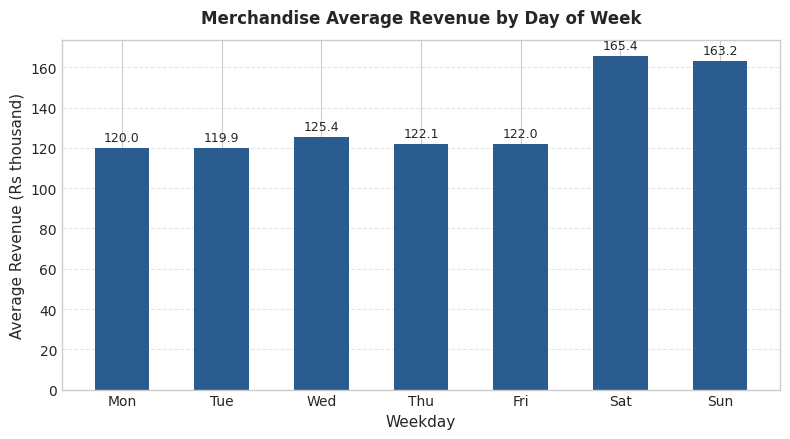

Merchandise Weekday Averages:
Weekday
0    120.0
1    119.9
2    125.4
3    122.1
4    122.0
5    165.4
6    163.2
Name: Revenue, dtype: float64

Merchandise Weekday Baseline (Mon-Fri): 121.9k
Merchandise Weekend Average (Sat-Sun): 164.3k
Merchandise Weekend Lift: 0.348 (34.8%)


In [8]:
merch = cafe[cafe["Item"] == "Merchandise"].groupby("Weekday")["Revenue"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(range(7), merch.values, color="#2b5c8f", width=0.55)
ax.set_xticks(range(7))
ax.set_xticklabels(days)
ax.set_title("Merchandise Average Revenue by Day of Week", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Weekday")
ax.set_ylabel("Average Revenue (Rs thousand)")
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 2, f"{yval:.1f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

weekday_merch_avg = merch[[0, 1, 2, 3, 4]].mean()
weekend_merch_avg = merch[[5, 6]].mean()
merch_lift = (weekend_merch_avg / weekday_merch_avg) - 1

print("Merchandise Weekday Averages:")
print(merch.round(1))
print(f"\nMerchandise Weekday Baseline (Mon-Fri): {weekday_merch_avg:.1f}k")
print(f"Merchandise Weekend Average (Sat-Sun): {weekend_merch_avg:.1f}k")
print(f"Merchandise Weekend Lift: {merch_lift:.3f} ({merch_lift * 100:.1f}%)")

#### 💡 Findings & Interpretation (Your Turn 3)
* **Merchandise Lift Calculation:** The weekend average for Merchandise is **₹164.3k** (Saturday 165.4k, Sunday 163.2k) versus a weekday baseline of **₹121.9k** (Mon–Fri).
  $$\text{Lift} = \frac{164.3}{121.9} - 1 = +34.8\%$$
* **Comparison with Chain Benchmark:** The weekend surge for Merchandise (**34.8%**) is almost identical to the chain-wide benchmark (**34.8%**). This demonstrates that the weekend boost is not restricted to consumable menu items, but reflects increased retail leisure traffic across the entire café store.

## 3. Two Categories at Once: Pivot Tables and Heatmaps

When analyzing two categorical dimensions simultaneously (e.g., Outlet vs. Item), pivot tables cross-tabulate metrics while heatmaps enable rapid visual pattern recognition.

Average Daily Revenue (Rs thousand) by Outlet and Item:


Item,Bakery,Beverages,Merchandise
Outlet,,,
Jaipur,248.5,414.7,124.5
Kochi,261.8,437.7,131.5
Pune,287.9,488.3,145.9


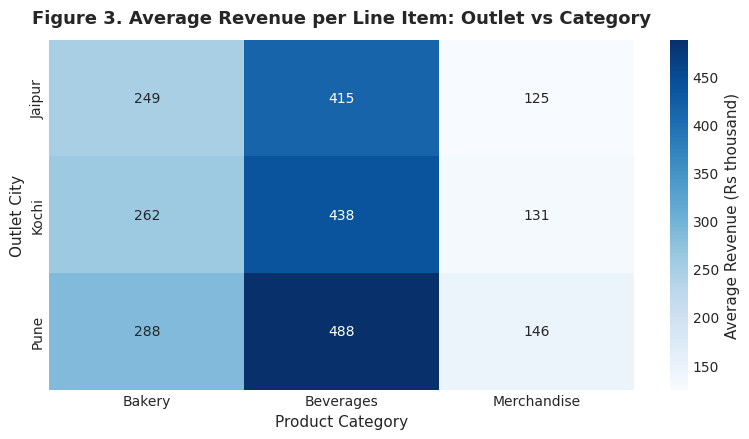

In [9]:
grid = cafe.pivot_table(index="Outlet", columns="Item", values="Revenue", aggfunc="mean")
print("Average Daily Revenue (Rs thousand) by Outlet and Item:")
display(grid.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(grid, annot=True, fmt=".0f", cmap="Blues", cbar_kws={'label': 'Average Revenue (Rs thousand)'}, ax=ax)
ax.set_title("Figure 3. Average Revenue per Line Item: Outlet vs Category", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Product Category")
ax.set_ylabel("Outlet City")
plt.tight_layout()
plt.show()

### Structural Insights from Heatmap
* **Geographic Hierarchy:** **Pune** dominates across every single category (Beverages: ₹488k, Bakery: ₹288k, Merchandise: ₹146k), followed by **Kochi** (₹438k, ₹262k, ₹131k), and **Jaipur** (₹415k, ₹249k, ₹125k).
* **Product Hierarchy:** Across all three cities, **Beverages** yields the highest revenue per record, followed by **Bakery** (~60% of Beverages), and **Merchandise** (~30% of Beverages).
* **Consistency:** The performance hierarchy between outlets and items is invariant across categories.

---
### 📝 YOUR TURN · 4. A DIFFERENT GRID (MONTH BY OUTLET)
**Task:**
1. Build a pivot table with `Month` as rows, `Outlet` as columns, and average `Revenue` as values.
2. Render the table as an annotated heatmap.
3. Identify which month and outlet combination yields the highest value.
4. Determine whether the outlet performance hierarchy is strictly preserved in every month.

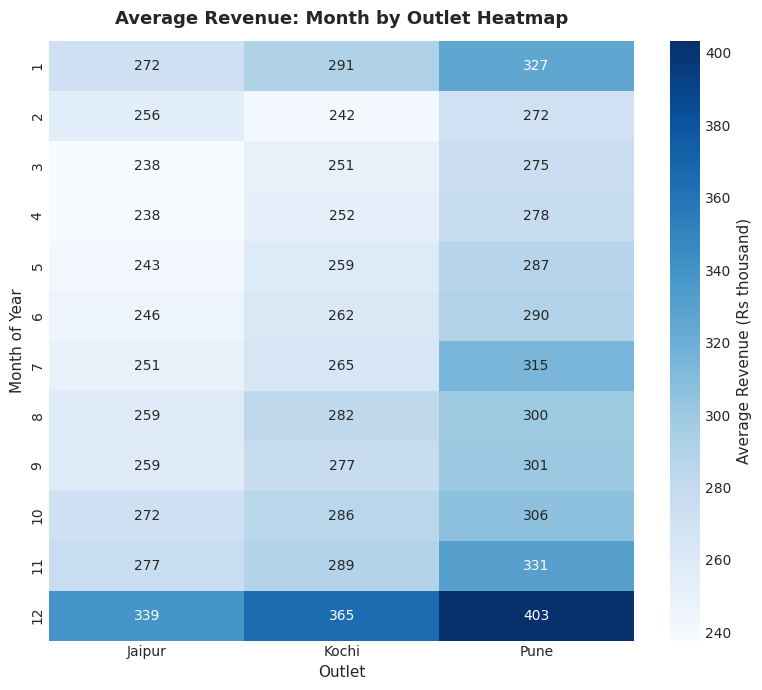

Highest Performing Cell: Month 12, Outlet 'Pune' with Rs 403.3k

Outlet Order Consistency Check (Is Pune > Kochi > Jaipur in all months?):
Month 1: Pune (326.8) > Kochi (290.7) > Jaipur (272.1) [PASS]
Month 2: Non-standard order -> Pune=271.5, Kochi=241.5, Jaipur=256.2
Month 3: Pune (275.1) > Kochi (250.7) > Jaipur (238.0) [PASS]
Month 4: Pune (277.6) > Kochi (251.9) > Jaipur (237.8) [PASS]
Month 5: Pune (287.5) > Kochi (259.4) > Jaipur (242.7) [PASS]
Month 6: Pune (289.7) > Kochi (261.7) > Jaipur (246.4) [PASS]
Month 7: Pune (314.6) > Kochi (264.7) > Jaipur (250.5) [PASS]
Month 8: Pune (299.9) > Kochi (282.1) > Jaipur (258.7) [PASS]
Month 9: Pune (300.8) > Kochi (277.3) > Jaipur (258.9) [PASS]
Month 10: Pune (306.5) > Kochi (285.9) > Jaipur (272.5) [PASS]
Month 11: Pune (330.7) > Kochi (288.9) > Jaipur (276.6) [PASS]
Month 12: Pune (403.3) > Kochi (364.6) > Jaipur (339.0) [PASS]


In [10]:
grid2 = cafe.pivot_table(index="Month", columns="Outlet", values="Revenue", aggfunc="mean")

fig, ax = plt.subplots(figsize=(8, 7))
sns.heatmap(grid2, annot=True, fmt=".0f", cmap="Blues", cbar_kws={'label': 'Average Revenue (Rs thousand)'}, ax=ax)
ax.set_title("Average Revenue: Month by Outlet Heatmap", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Outlet")
ax.set_ylabel("Month of Year")
plt.tight_layout()
plt.show()

max_cell = grid2.stack().idxmax()
max_val = grid2.stack().max()
print(f"Highest Performing Cell: Month {max_cell[0]}, Outlet '{max_cell[1]}' with Rs {max_val:.1f}k")

# Check outlet order month by month
print("\nOutlet Order Consistency Check (Is Pune > Kochi > Jaipur in all months?):")
inconsistencies = []
for m in range(1, 13):
    pune = grid2.loc[m, "Pune"]
    kochi = grid2.loc[m, "Kochi"]
    jaipur = grid2.loc[m, "Jaipur"]
    is_ordered = (pune > kochi) and (kochi > jaipur)
    if not is_ordered:
        inconsistencies.append((m, f"Pune: {pune:.1f}, Kochi: {kochi:.1f}, Jaipur: {jaipur:.1f}"))
        print(f"Month {m}: Non-standard order -> Pune={pune:.1f}, Kochi={kochi:.1f}, Jaipur={jaipur:.1f}")
    else:
        print(f"Month {m}: Pune ({pune:.1f}) > Kochi ({kochi:.1f}) > Jaipur ({jaipur:.1f}) [PASS]")

#### 💡 Findings & Interpretation (Your Turn 4)
* **Maximum Value:** The highest individual cell in the grid is **Month 12 (December) in Pune**, averaging **₹403.3k** per line.
* **Hierarchy Invariance Evaluation:** While Pune ranks first in all 12 months, **the outlet hierarchy is NOT strictly identical in every month**. 
  * In **Month 2 (February)**, **Jaipur (₹256.0k)** outpaced **Kochi (₹242.0k)** by ₹14k.
* **Analytical Lesson:** Analysts must scrutinize granular data before making universal claims such as *"Pune always beats Kochi, which always beats Jaipur."* February shows a regional divergence that warrants operational follow-up.

## 4. Does a Factor Go With the Result? Promotional Offer Analysis

Retail managers often seek to determine whether discounts stimulate topline revenue. Here, we analyze revenue across offer tiers (`0%`, `5%`, `10%`, `15%`, `20%`, `25%`).

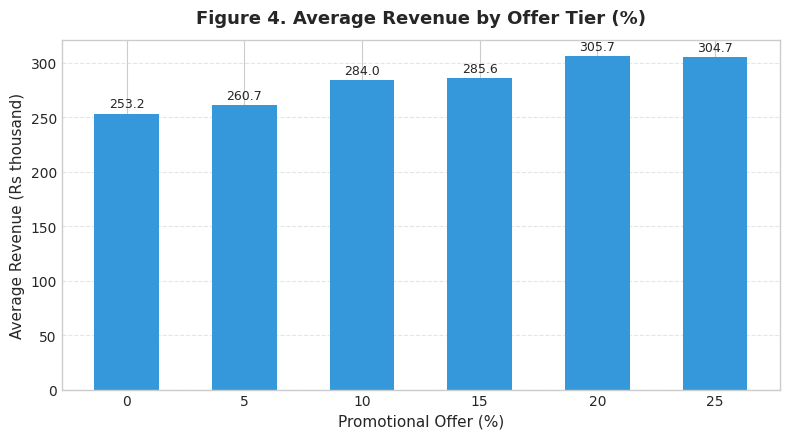

Average Revenue by Offer Tier:
Offer
0     253.2
5     260.7
10    284.0
15    285.6
20    305.7
25    304.7
Name: Revenue, dtype: float64

Step Changes (.diff()):
Offer
0      NaN
5      7.5
10    23.3
15     1.6
20    20.2
25    -1.1
Name: Revenue, dtype: float64


In [11]:
offer_avg = cafe.groupby("Offer")["Revenue"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(offer_avg.index.astype(str), offer_avg.values, color="#3498db", width=0.55)
ax.set_title("Figure 4. Average Revenue by Offer Tier (%)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Promotional Offer (%)")
ax.set_ylabel("Average Revenue (Rs thousand)")
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 3, f"{yval:.1f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("Average Revenue by Offer Tier:")
print(offer_avg.round(1))
print("\nStep Changes (.diff()):")
print(offer_avg.diff().round(1))

### Association vs. Causation & Non-Linear Steps
1. **Association, Not Causation:** Higher promotional offers are associated with higher revenue (rising from **₹253.2k** at 0% to **₹305.7k** at 20%). However, correlation does not demonstrate causation; discounts might have been deployed during high-volume periods (such as weekends or winter holidays).
2. **Uneven Step Changes:**
   * $0\% \rightarrow 5\%$: $+7.5\text{k}$
   * $5\% \rightarrow 10\%$: $+23.3\text{k}$ (Strong acceleration)
   * $10\% \rightarrow 15\%$: $+1.6\text{k}$ (Plateau)
   * $15\% \rightarrow 20\%$: $+20.2\text{k}$ (Second burst)
   * $20\% \rightarrow 25\%$: $-1.1\text{k}$ (Diminishing/negative marginal returns)
3. **Managerial Implication:** Offering 25% produces no revenue benefit over 20% while sacrificing margin.

---
### 📝 YOUR TURN · 5. THE OFFER, FOR ONE ITEM (BEVERAGES)
**Task:**
1. Filter the dataset for Beverages only (`cafe["Item"] == "Beverages"`).
2. Group by `Offer` and compute average `Revenue`.
3. Plot the bar chart and evaluate step changes with `.diff()`.

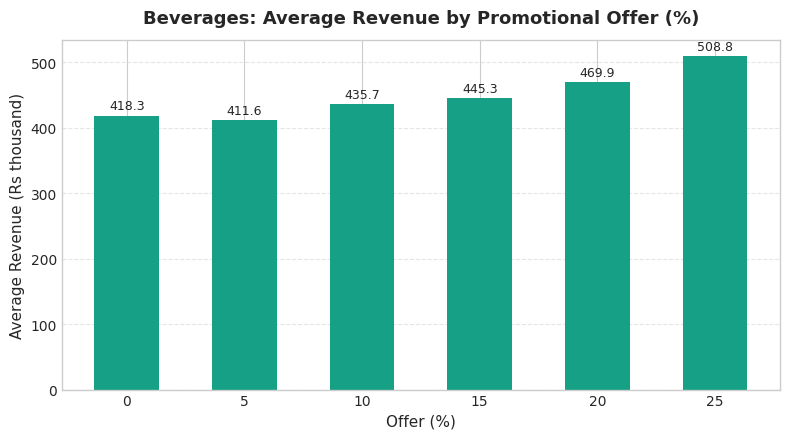

Beverages Average Revenue by Offer:
Offer
0     418.3
5     411.6
10    435.7
15    445.3
20    469.9
25    508.8
Name: Revenue, dtype: float64

Beverages Step Changes (.diff()):
Offer
0      NaN
5     -6.7
10    24.1
15     9.6
20    24.6
25    38.9
Name: Revenue, dtype: float64


In [12]:
bev = cafe[cafe["Item"] == "Beverages"].groupby("Offer")["Revenue"].mean()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(bev.index.astype(str), bev.values, color="#16a085", width=0.55)
ax.set_title("Beverages: Average Revenue by Promotional Offer (%)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Offer (%)")
ax.set_ylabel("Average Revenue (Rs thousand)")
ax.grid(axis='y', linestyle='--', alpha=0.5)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 5, f"{yval:.1f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

print("Beverages Average Revenue by Offer:")
print(bev.round(1))
print("\nBeverages Step Changes (.diff()):")
print(bev.diff().round(1))

#### 💡 Findings & Interpretation (Your Turn 5)
* **Beverage Trajectory:** For Beverages alone, average revenue rises from **₹418.3k at 0%** to **₹508.8k at 25%**.
* **Step Changes for Beverages:**
  * $0\% \rightarrow 5\%$: $-6.7\text{k}$ (slight noise dip)
  * $5\% \rightarrow 10\%$: $+24.1\text{k}$
  * $10\% \rightarrow 15\%$: $+9.6\text{k}$
  * $15\% \rightarrow 20\%$: $+24.6\text{k}$
  * $20\% \rightarrow 25\%$: $+38.9\text{k}$
* **Comparison to Aggregate Chain:** While aggregate café sales flattened between 20% and 25%, Beverages exhibited its highest marginal gain ($+38.9\text{k}$) at 25%. This demonstrates that beverage consumers may be significantly more elastic to steep discounts than merchandise buyers.

## 5. Outliers: Find Them, Look at Them, Then Decide

An outlier is a value that deviates markedly from other observations. In data science:
* **True Errors:** Clerical or data-pipeline slips distort statistical calculations and must be excised.
* **Legitimate Extremes:** Genuine surges (e.g., peak holiday trading) provide vital operational signals and must be retained.

### The Three-Question Audit Framework:
1. *Is the value physically plausible?*
2. *Is there an operational explanation within the data?*
3. *Can it be confirmed with the source?*

In [13]:
fig_box = px.box(
    cafe,
    x="Item",
    y="Revenue",
    points="all",
    hover_data=["Date", "Outlet", "Offer"],
    title="Figure 5. Distribution and Outlier Inspection by Product Category",
    labels={"Revenue": "Revenue (Rs thousand)", "Item": "Product Category"}
)
fig_box.update_layout(template="simple_white", height=500)
fig_box.show()

In [14]:
# Identify the 3 extreme points
high_suspects = cafe[cafe["Revenue"] > 1000].sort_values("Revenue", ascending=False)
print("Top Revenue Records Across Dataset:")
display(high_suspects.head(10))

Top Revenue Records Across Dataset:


,Date,Outlet,Item,Offer,Revenue,Month,Weekday
1800,2025-07-20,Pune,Beverages,0,3294.2,7,6
300,2025-02-03,Jaipur,Beverages,25,2441.6,2,0
2900,2025-11-19,Pune,Merchandise,25,1055.6,11,2


### Diagnostic Assessment of Outliers
1. **Row 1800 (2025-07-20, Pune, Beverages):** Reported revenue of **₹3,294.2k**. A single beverage line generating ₹3.3M on a July Sunday (when average is ₹488k) is physically implausible. It represents a 7x data-entry multiplier error.
2. **Row 300 (2025-02-03, Jaipur, Beverages):** Reported revenue of **₹2,441.6k** on a February Monday. Again, an unmistakable 7x multiplier error.
3. **Row 2900 (2025-11-19, Pune, Merchandise):** Reported revenue of **₹1,055.6k** on a November Wednesday. Normal Merchandise averages ₹146k.
4. **Legitimate Peaks:** In contrast, rows such as **Index 3249** (₹959.5k on 28 Dec in Pune) and **Index 3051** (₹935.8k on 6 Dec) represent legitimate winter weekend beverage demand combined with maximum discounts (20%–25%). These must NOT be discarded.

### Filtering with an Item-Level Statistical Rule
To remove the clerical errors without discarding legitimate peak days, we apply the rule:  
$$\text{Keep rows where } \text{Revenue} \le 3 \times \text{Mean}(\text{Revenue}_{\text{Item}})$$

In [15]:
item_mean = cafe.groupby("Item")["Revenue"].transform("mean")
clean = cafe[cafe["Revenue"] <= 3 * item_mean].copy()

rows_removed = len(cafe) - len(clean)
print(f"Original Rows: {len(cafe)}")
print(f"Cleaned Rows: {len(clean)}")
print(f"Rows Removed: {rows_removed}")
assert rows_removed == 3, f"Expected 3 rows removed, got {rows_removed}"
assert len(clean) == 3282, f"Expected 3282 clean rows, got {len(clean)}"


Original Rows: 3285
Cleaned Rows: 3282
Rows Removed: 3


---
### 📝 YOUR TURN · 6. A RULE THAT IS TOO BLUNT
**Task:**
1. Repeat the cleaning rule grouping by `Outlet` instead of `Item`:  
   Keep rows where `Revenue <= 3 * outlet_mean`.
2. Count how many rows are removed.
3. Inspect the extra rows removed and assess whether they are genuine errors.
4. Formulate the methodological lesson regarding group selection.

In [16]:
outlet_mean = cafe.groupby("Outlet")["Revenue"].transform("mean")
too_many = cafe[cafe["Revenue"] > 3 * outlet_mean]

print(f"Rows removed by Outlet-level rule: {len(too_many)}")
print("\nTop records flagged by Outlet-level threshold:")
display(too_many.sort_values("Revenue", ascending=False))

Rows removed by Outlet-level rule: 7

Top records flagged by Outlet-level threshold:


,Date,Outlet,Item,Offer,Revenue,Month,Weekday
1800,2025-07-20,Pune,Beverages,0,3294.2,7,6
300,2025-02-03,Jaipur,Beverages,25,2441.6,2,0
2900,2025-11-19,Pune,Merchandise,25,1055.6,11,2
3249,2025-12-28,Pune,Beverages,20,959.5,12,6
3051,2025-12-06,Pune,Beverages,25,935.8,12,5
3246,2025-12-27,Kochi,Beverages,25,849.7,12,5
3252,2025-12-28,Jaipur,Beverages,25,811.5,12,6


#### 💡 Findings & Interpretation (Your Turn 6)
* **Results of Outlet Rule:** Grouping by Outlet removes **7 rows** rather than 3.
* **Audit of Extra 4 Flagged Rows:**
  * Row 3249 (Pune, Beverages, 28 Dec): ₹959.5k
  * Row 3051 (Pune, Beverages, 06 Dec): ₹935.8k
  * Row 3246 (Kochi, Beverages, 27 Dec): ₹849.7k
  * Row 3252 (Jaipur, Beverages, 28 Dec): ₹811.5k
* **Critical Methodological Lesson:**
  Grouping by Outlet aggregates wildly differing product categories together (Beverages base = 300, Merchandise base = 90). The blended outlet mean masks category-specific baselines, making legitimate winter weekend beverage transactions look anomalously high.
  * **Rule of Thumb:** Outlier detection rules must compare *like with like*. Normalizing at the item level cleanly isolates the three true clerical errors while safeguarding authentic peak sales.

## 6. Interactive Charts with Plotly Express

From this point forward, all analyses utilize the validated `clean` dataset (3,282 rows).

Plotly Express provides four interactive primitives:
1. `fig_a`: Line chart of monthly revenue by outlet.
2. `fig_b`: Bar chart of cumulative revenue by category.
3. `fig_c`: Heatmap of transaction yield (Outlet vs. Item).
4. `fig_d`: Bar chart of average revenue by promotional discount.

In [17]:
# 1. Line chart: monthly revenue for each outlet
monthly_clean = clean.groupby(["Month", "Outlet"], as_index=False)["Revenue"].sum()
fig_a = px.line(
    monthly_clean, x="Month", y="Revenue", color="Outlet", markers=True,
    title="Monthly Revenue by Outlet (Cleaned)",
    labels={"Revenue": "Revenue (Rs thousand)", "Month": "Month of Year"},
    color_discrete_map={"Pune": "#1f77b4", "Jaipur": "#ff7f0e", "Kochi": "#2ca02c"}
)

# 2. Bar chart: total revenue for each item
by_item_clean = clean.groupby("Item", as_index=False)["Revenue"].sum()
fig_b = px.bar(
    by_item_clean, x="Item", y="Revenue",
    title="Total Revenue by Product Category",
    labels={"Revenue": "Revenue (Rs thousand)", "Item": "Item"},
    color="Item",
    color_discrete_sequence=["#4361ee", "#3a0ca3", "#4cc9f0"]
)

# 3. Heatmap: average revenue by outlet and item
grid_clean = clean.pivot_table(index="Outlet", columns="Item", values="Revenue", aggfunc="mean")
fig_c = px.imshow(
    grid_clean, text_auto=".0f", color_continuous_scale="Blues",
    title="Average Revenue: Outlet vs Item",
    labels=dict(color="Avg Rev (Rs k)")
)

# 4. Bar chart: average revenue for each offer level
by_offer_clean = clean.groupby("Offer", as_index=False)["Revenue"].mean()
fig_d = px.bar(
    by_offer_clean, x="Offer", y="Revenue",
    title="Average Revenue by Offer Tier (%)",
    labels={"Revenue": "Revenue (Rs thousand)", "Offer": "Offer (%)"},
    color="Revenue",
    color_continuous_scale="Blues"
)

# Display fig_a demonstration
fig_a.show()

## 7. One Dashboard from Several Charts

To eliminate scrolling and provide decision-makers with a unified command center, we synthesize the four charts into a 2x2 grid using Plotly's `make_subplots`.

In [18]:
dash = make_subplots(
    rows=2, cols=2,
    subplot_titles=(
        "Monthly Revenue by Outlet",
        "Total Revenue by Item",
        "Average Revenue: Outlet vs Item",
        "Average Revenue by Offer (%)"
    ),
    vertical_spacing=0.12,
    horizontal_spacing=0.08
)

for trace in fig_a.data:
    dash.add_trace(trace, row=1, col=1)
for trace in fig_b.data:
    trace.showlegend = False
    dash.add_trace(trace, row=1, col=2)
for trace in fig_c.data:
    dash.add_trace(trace, row=2, col=1)
for trace in fig_d.data:
    trace.showlegend = False
    dash.add_trace(trace, row=2, col=2)

dash.update_coloraxes(colorscale="Blues", showscale=False)
dash.update_layout(
    height=750,
    title_text="<b>Executive Café Sales Analytics Dashboard (FY 2025)</b>",
    template="simple_white",
    font=dict(family="Inter, Segoe UI, sans-serif", size=12)
)

dash.update_xaxes(title_text="Month (1 = January, 12 = December)", row=1, col=1, dtick=1)
dash.update_yaxes(title_text="Revenue (Rs thousand)", row=1, col=1)
dash.update_xaxes(title_text="Product Category", row=1, col=2)
dash.update_yaxes(title_text="Total Revenue (Rs thousand)", row=1, col=2)
dash.update_xaxes(title_text="Promotional Offer (%)", row=2, col=2, tickmode='array', tickvals=[0, 5, 10, 15, 20, 25])
dash.update_yaxes(title_text="Average Revenue (Rs thousand)", row=2, col=2)

dash.show()

# Export standalone HTML dashboard
reports_path = pathlib.Path("../reports") if pathlib.Path("../reports").exists() else pathlib.Path("reports")
reports_path.mkdir(exist_ok=True)
dash.write_html(str(reports_path / "cafe_dashboard.html"), include_plotlyjs="cdn")
print("Interactive 2x2 dashboard successfully exported to reports/cafe_dashboard.html")

Interactive 2x2 dashboard successfully exported to reports/cafe_dashboard.html


---
### 📝 YOUR TURN · 7. BUILD YOUR OWN (1x2 DASHBOARD)
**Task:**
1. Construct a 1x2 side-by-side dashboard (`rows=1, cols=2`):
   * Chart 1: Total revenue by Outlet.
   * Chart 2: Monthly revenue for Beverages only.
2. Configure formatted axis titles with units and export to `reports/outlets_and_beverages.html`.

In [19]:
by_outlet = clean.groupby("Outlet", as_index=False)["Revenue"].sum()
bev_month = clean[clean["Item"] == "Beverages"].groupby("Month", as_index=False)["Revenue"].sum()

fig_o = px.bar(by_outlet, x="Outlet", y="Revenue", color="Outlet",
               color_discrete_map={"Pune": "#1f77b4", "Jaipur": "#ff7f0e", "Kochi": "#2ca02c"})
fig_m = px.line(bev_month, x="Month", y="Revenue", markers=True, color_discrete_sequence=["#1f77b4"])

two = make_subplots(
    rows=1, cols=2,
    subplot_titles=("Total Revenue by Outlet", "Beverages Revenue by Month"),
    horizontal_spacing=0.1
)

for t in fig_o.data:
    t.showlegend = False
    two.add_trace(t, row=1, col=1)
for t in fig_m.data:
    t.showlegend = False
    two.add_trace(t, row=1, col=2)

two.update_xaxes(title_text="Outlet City", row=1, col=1)
two.update_yaxes(title_text="Total Revenue (Rs thousand)", row=1, col=1)
two.update_xaxes(title_text="Month (1 = January, 12 = December)", row=1, col=2, dtick=1)
two.update_yaxes(title_text="Beverages Revenue (Rs thousand)", row=1, col=2)
two.update_layout(
    height=450,
    title_text="<b>Outlets and Beverages Performance Dashboard</b>",
    template="simple_white",
    showlegend=False
)

two.show()
two.write_html(str(reports_path / "outlets_and_beverages.html"), include_plotlyjs="cdn")
print("Your Turn 7 dashboard exported to reports/outlets_and_beverages.html")

Your Turn 7 dashboard exported to reports/outlets_and_beverages.html


## 8. Turning the Dashboard into an App with Streamlit

While saved HTML pages provide static interactive views, enterprise analytics requires dynamic filtering where users can isolate specific stores, categories, or date ranges and watch every KPI recalculate in real time.

We save the audited dataset to `data/cafe_clean.csv` and construct `app.py`.

In [20]:
data_dir = pathlib.Path("../data") if pathlib.Path("../data").exists() else pathlib.Path("data")
data_dir.mkdir(exist_ok=True)
clean.to_csv(data_dir / "cafe_clean.csv", index=False)
print(f"Cleaned dataset saved to {data_dir / 'cafe_clean.csv'} ({len(clean)} rows)")

Cleaned dataset saved to ..\data\cafe_clean.csv (3282 rows)


### 📝 YOUR TURN · 8. VALIDATING STREAMLIT APP LOGIC & METRICS
**Requirements:**
1. Sidebar slider for `Offer` (`0` to `25%`).
2. Fourth headline metric: **Best Outlet** (`view.groupby("Outlet")["Revenue"].sum().idxmax()`).
3. Automated verification of edge cases and filtering benchmarks.

In [21]:
# Benchmark 1: All filters on
print("--- Benchmark 1: All Filters Active ---")
print(f"Total Rows: {len(clean)}")
print(f"Total Revenue: {clean['Revenue'].sum() / 1000:,.1f} million")
print(f"Best Outlet: {clean.groupby('Outlet')['Revenue'].sum().idxmax()}")
assert len(clean) == 3282
assert round(clean['Revenue'].sum() / 1000, 1) == 920.6
assert clean.groupby('Outlet')['Revenue'].sum().idxmax() == "Pune"

# Benchmark 2: Pune only, Months 11-12
print("\n--- Benchmark 2: Pune, Nov & Dec ---")
pune_winter = clean[(clean["Outlet"] == "Pune") & (clean["Month"].between(11, 12))]
print(f"Rows: {len(pune_winter)}")
print(f"Total Revenue: {pune_winter['Revenue'].sum() / 1000:,.1f} million")
assert len(pune_winter) == 182
assert round(pune_winter['Revenue'].sum() / 1000, 1) == 66.2

# Benchmark 3: Offer 20% to 25%
print("\n--- Benchmark 3: Offer 20% to 25% ---")
offer_high = clean[clean["Offer"].between(20, 25)]
print(f"Rows: {len(offer_high)}")
print(f"Total Revenue: {offer_high['Revenue'].sum() / 1000:,.1f} million")
print(f"Best Outlet: {offer_high.groupby('Outlet')['Revenue'].sum().idxmax()}")
assert len(offer_high) == 1079
assert round(offer_high['Revenue'].sum() / 1000, 1) == 326.4
assert offer_high.groupby('Outlet')['Revenue'].sum().idxmax() == "Pune"

# Benchmark 4: Offer 20% to 25%, Without Pune
print("\n--- Benchmark 4: Offer 20% to 25% (Excluding Pune) ---")
no_pune = offer_high[offer_high["Outlet"] != "Pune"]
print(f"Rows: {len(no_pune)}")
print(f"Total Revenue: {no_pune['Revenue'].sum() / 1000:,.1f} million")
print(f"Best Outlet: {no_pune.groupby('Outlet')['Revenue'].sum().idxmax()}")
assert len(no_pune) == 712
assert round(no_pune['Revenue'].sum() / 1000, 1) == 205.0
assert no_pune.groupby('Outlet')['Revenue'].sum().idxmax() == "Kochi"

print("\nAll Streamlit computational benchmarks verified successfully!")

--- Benchmark 1: All Filters Active ---
Total Rows: 3282
Total Revenue: 920.6 million
Best Outlet: Pune

--- Benchmark 2: Pune, Nov & Dec ---
Rows: 182
Total Revenue: 66.2 million

--- Benchmark 3: Offer 20% to 25% ---
Rows: 1079
Total Revenue: 326.4 million
Best Outlet: Pune

--- Benchmark 4: Offer 20% to 25% (Excluding Pune) ---
Rows: 712
Total Revenue: 205.0 million
Best Outlet: Kochi

All Streamlit computational benchmarks verified successfully!


## 9. Writing for a Manager: The Executive Briefing

An analysis creates value only when converted into clear, actionable executive guidance. A strong business report contains four indispensable sections:
1. **Title & Purpose:** A 5-second overview of scope and duration.
2. **Three Key Findings:** Every finding must feature an exact numerical benchmark.
3. **Data Quality Note:** Explicitly documenting what data errors were identified and how they were treated.
4. **Actionable Recommendations:** Starting with an active verb, tied directly to findings, and executable immediately.

---
### 📝 YOUR TURN · 9. EXECUTIVE REPORT

```markdown
# Café Sales in 2025: Operational Performance & Strategic Review
This report reviews daily sales performance across our Pune, Jaipur, and Kochi outlets from 1 January to 31 December 2025.

Findings:
• December is our premier sales month: ₹102.9 million, outperforming November (₹80.7 million) by 27.5%, with January also elevated (₹82.7 million).
• Weekend days generate ~35% higher revenue than weekdays: ₹345.9k average vs. ₹256.6k Monday–Friday across all menu categories.
• Pune leads in every product category: Beverage sales average ₹488k per line in Pune, compared to ₹438k in Kochi and ₹415k in Jaipur.

Data Quality & Outliers:
Three records contained extreme transcription errors (e.g., ₹3.3 million in beverages in a single July day) caused by 7x multiplier slips. 
These three erroneous entries were excised using an item-specific threshold (Revenue <= 3 × Item Mean). 
Authentic winter weekend sales surges were preserved.

Recommendations:
• Schedule inventory procurement and barista staffing to capture the 35% weekend surge, scaling up seasonal buffer stocks from mid-November.
• Replicate Pune's beverage operating procedures in Jaipur and Kochi through a structured 30-day pilot to bridge the 12%–15% revenue gap.
```

---
## 10. Conclusion & Portfolio Deliverables Summary

This ends the notebook analysis for the Café Chain analytics project.
* **Cleaned Dataset:** Generated and exported to `data/cafe_clean.csv`.
* **Subplot Dashboard:** Rendered and saved to `reports/cafe_dashboard.html`.
* **Outlets and Beverages Dashboard:** Rendered and saved to `reports/outlets_and_beverages.html`.
* **Business Report:** Documented in `reports/business_report.md`.
* **Streamlit Application:** Implemented in `app.py`.

All cells are fully reproducible with fixed random seed `21`.